# Symmetries as inductive bias: the notebook behind the briefing

This notebook goes with the briefing page [Symmetry Thesis Briefing](https://claude.ai/artifact/JZFhh6N9EPqokuGKiFdmtr)
and follows its eight sections. Every table is read
from the run directories (`best.json`, `history.json`, job logs) or computed here, so each number can be traced to a file.
Two notebooks show the models in detail: `notebooks/facet_model.ipynb` (one puzzle through the facet model) and
`notebooks/value_axis.ipynb` (one puzzle through the value axis).

Cells are **matched % (exact %)** on unseen puzzles (I-RAVEN val 300+, I-RAVEN-X 6300+), with the epoch picked on the
selection puzzles. *Matched*: the candidate closest to the generated answer is right (ties wrong, chance 12.5%).
*Exact*: the generated panel equals the answer. One seed unless a cell says otherwise.

In [1]:
import os, sys, json, re, glob, warnings
from collections import Counter
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
from IPython.display import display, Markdown, SVG
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")   # paths below are relative to the repo root
sys.path[:0] = [os.path.abspath("core/pynl"), os.path.abspath("analysis")]; sys.path.insert(0, os.path.abspath("."))
E, RUNS = "experiments", "experiments/baselines/runs"

def facet(d):
    """A facet-model run: unseen matched % and exact % (its best.json stores counts)."""
    u = json.load(open(f"{E}/{d}/best.json"))["unseen"]
    n = sum(t for _, t in u["per_constellation"].values())
    return 100 * u["matched"] / n, 100 * u["exact"] / n

def torch_run(d, seeds=(0,), key=None):
    """A torch run: unseen matched % and exact %, the mean over seeds; key picks another record (a transform)."""
    rs = [json.load(open(f"{RUNS}/{d}_s{s}/best.json")) for s in seeds]
    rs = [r["transforms"][key] if key else r["best"]["unseen"] for r in rs]
    return np.mean([100 * r["matched"] for r in rs]), np.mean([100 * r["exact"] for r in rs])

def rule_exact(rec, rule):
    h, t = rec["exact_per_rule"][rule]
    return 100 * h / t

def cell(me):
    return "–" if me is None else f"{me[0]:.1f} ({me[1]:.1f})"

def table(header, rows):
    display(Markdown("| " + " | ".join(header) + " |\n|" + "---|" * len(header) + "\n"
                     + "\n".join("| " + " | ".join(str(c) for c in r) + " |" for r in rows)))

PALETTE = ["#2b6cb0", "#c05621", "#2f855a", "#805ad5", "#b83280", "#4a5568", "#b7791f"]
def chart(series, title, xticks, xmax, ylabel="matched %", w=680, h=300):
    """Lines on one 0-100 axis. series: [(name, [(x, y), ...])]; xticks: [(x, label)]."""
    L, Rm, T, Bm = 48, 200, 34, 40
    pw, ph = w - L - Rm, h - T - Bm
    X, Y = (lambda x: L + pw * x / xmax), (lambda v: T + ph * (1 - v / 100))
    s = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{w}" height="{h}" viewBox="0 0 {w} {h}" '
         f'font-family="Helvetica, Arial, sans-serif" font-size="12"><rect width="{w}" height="{h}" fill="white"/>',
         f'<text x="{L}" y="18" font-size="13" font-weight="bold" fill="#1a202c">{title}</text>']
    for g in range(0, 101, 20):
        s += [f'<line x1="{L}" x2="{L + pw}" y1="{Y(g):.1f}" y2="{Y(g):.1f}" stroke="#e2e8f0"/>',
              f'<text x="{L - 6}" y="{Y(g) + 4:.1f}" text-anchor="end" fill="#4a5568">{g}</text>']
    s += [f'<text x="{X(x):.1f}" y="{T + ph + 18}" text-anchor="middle" fill="#4a5568">{t}</text>' for x, t in xticks]
    s.append(f'<text x="13" y="{T + ph / 2:.0f}" transform="rotate(-90 13 {T + ph / 2:.0f})" text-anchor="middle" '
             f'fill="#4a5568">{ylabel}</text>')
    ends = []
    for k, (name, pts) in enumerate(series):
        c, pts = PALETTE[k % len(PALETTE)], [(X(x), Y(y)) for x, y in pts]
        s.append(f'<polyline fill="none" stroke="{c}" stroke-width="2" points="{" ".join(f"{x:.1f},{y:.1f}" for x, y in pts)}"/>')
        s += [f'<circle cx="{x:.1f}" cy="{y:.1f}" r="2.5" fill="{c}"/>' for x, y in pts] if len(pts) < 40 else []
        ends.append([pts[-1][1], name, c])
    ends.sort()
    for j in range(1, len(ends)):                       # end labels at least 14 px apart
        ends[j][0] = max(ends[j][0], ends[j - 1][0] + 14)
    s += [f'<text x="{L + pw + 10}" y="{y + 4:.1f}" fill="{c}">{name}</text>' for y, name, c in ends]
    return SVG("".join(s) + "</svg>")
print("ready")

ready


## 1. The facet model

The facet model **generates** the missing panel and only then picks the closest candidate; it never sees the candidates,
not even in training. One node per (object, attribute), values as thermometer codes, a graph grounded for every puzzle.
The template names no object, row, component or attribute, so renaming them cannot change any output: that is how its
symmetries are built in (notes §21.2).

**The theorem, checked here.** Each transformation below is applied to one unseen puzzle per I-RAVEN layout, and the
largest change of any output is reported, over two draws of random weights. Zero (to rounding) means the symmetry is built in.
Per-panel copy gates name the panels, so rows 1 ↔ 2 is no longer built in; content gates restore it. Columns 1 ↔ 2 is a
control that no model has. The positions channel names its slots, so the mirror is built in for attributes only. The last
column runs the trained checkpoint and counts the puzzles whose chosen candidate changes.

In [2]:
import neuralogic
neuralogic.set_max_memory_size(16)
from neuralogic.logging import clear_handlers; clear_handlers()
from neuralogic.core import Settings
from neuralogic.nn import Adam, MSE
import bench_hub_grounding as B, facet_symmetry_check as FS

puzzles = B.load("data/I-RAVEN-10000", list(B.POS_MAP), "val", 300, 1)      # one unseen puzzle per layout

def facet_model(ckpt=None, **kw):
    m = B.build_facet_template(32, 2, True, True, [32, 64, 128], **kw)
    m.build(Settings(optimizer=Adam(lr=3e-4), error_function=MSE(), iso_value_compression=False))
    if ckpt:
        m.load(f"{ckpt}/template_best.bin")
    return m

cols = {}
for label, kw in [("facet", {}), ("copy links, per-panel gates", {"copy": True}),
                  ("copy links, content gates", {"copy": True, "gates": "content"})]:
    r = FS.run(facet_model(**kw), puzzles, kw.get("copy", False), draws=2)
    cols[label] = {k: f"{v['diff']:.0e}" if v else "n/a" for k, v in r.items()}
r = FS.run(facet_model(f"{E}/facet_all_w32-64-128_hidden"), puzzles, False, None)
cols["trained facet: answers moved"] = {k: f"{v['moved']} of {v['n']}" if v else "n/a" for k, v in r.items()}
table(["transformation"] + list(cols), [[k] + [cols[c][k] for c in cols] for k in FS.CHECKS
                                         if any(cols[c][k] != "n/a" for c in cols)])

| transformation | facet | copy links, per-panel gates | copy links, content gates | trained facet: answers moved |
|---|---|---|---|---|
| objects (order within a panel) | 2e-16 | 4e-16 | 3e-16 | 0 of 7 |
| rows 1 <-> 2 | 2e-16 | 9e-01 | 3e-16 | 0 of 7 |
| attributes type <-> colour | 0e+00 | 0e+00 | 0e+00 | 0 of 7 |
| components (mirror L-R), attributes | 0e+00 | 0e+00 | 0e+00 | 0 of 1 |
| components (mirror L-R), positions | 7e-01 | 4e-01 | 7e-01 | 0 of 1 |
| candidates (order) | 0e+00 | 0e+00 | 0e+00 | 0 of 7 |
| control: columns 1 <-> 2 | 5e-01 | 9e-01 | 5e-01 | 2 of 7 |

**Its variations on I-RAVEN-X 3×10, values 0–50.** Weights are from `docs/RESULTS.md` §9 (read from the checkpoints).

In [3]:
variants = [("named columns (plain facet)", "facet_iravenx_n10_m50", "1,411k"),
            ("+ copy links, per-panel gates", "facet_iravenx_n10_m50_copy", "1,598k"),
            ("+ copy links, content gates", "facet_iravenx_n10_m50_copy_content", "1,436k"),
            ("+ copy links, shuffled sources (control)", "facet_iravenx_n10_m50_copy_shuffled", "1,598k"),
            ("column roles", "facet_iravenx_n10_m50_roles", "288k"),
            ("column roles, widths 64/144/288", "facet_iravenx_n10_m50_roles_wide", "1,390k"),
            ("column roles + content gates", "facet_iravenx_n10_m50_roles_content", "314k"),
            ("row fold", "facet_iravenx_n10_m50_fold", "305k")]
table(["variant", "weights", "matched (exact)", "run"], [[n, w, cell(facet(d)), f"`{d}`"] for n, d, w in variants])

| variant | weights | matched (exact) | run |
|---|---|---|---|
| named columns (plain facet) | 1,411k | 85.4 (15.0) | `facet_iravenx_n10_m50` |
| + copy links, per-panel gates | 1,598k | 97.8 (60.0) | `facet_iravenx_n10_m50_copy` |
| + copy links, content gates | 1,436k | 94.9 (51.7) | `facet_iravenx_n10_m50_copy_content` |
| + copy links, shuffled sources (control) | 1,598k | 87.3 (21.5) | `facet_iravenx_n10_m50_copy_shuffled` |
| column roles | 288k | 94.1 (29.0) | `facet_iravenx_n10_m50_roles` |
| column roles, widths 64/144/288 | 1,390k | 94.9 (28.5) | `facet_iravenx_n10_m50_roles_wide` |
| column roles + content gates | 314k | 96.3 (43.3) | `facet_iravenx_n10_m50_roles_content` |
| row fold | 305k | 92.2 (28.0) | `facet_iravenx_n10_m50_fold` |

### The recursive version: the row fold (notes §25)

The row fold reads a row with a running state that one recursive rule moves along it, a panel at a time
(`--columns fold`). Below: its rules as the template prints them, its weights at three row lengths, and its symmetries
on random weights, on five unseen I-RAVEN-X 3×10 puzzles. One transition serves every step, so the template names no
column and its weights do not depend on the row length. Being a fold, it reads the row in order, so the middle columns
are not interchangeable.

In [4]:
B.configure(n_cols=10, maxval=50)               # I-RAVEN-X 3x10, values 0..50 (the cells above used I-RAVEN's defaults)
print("\n".join(l for l in str(B.build_facet_template(32, 2, True, True, [32, 64, 128], cols="fold")).splitlines()
                if "acc(" in l))
nweights = lambda m: sum(np.asarray(v).size for v in m.state_dict()["weights"].values())
rows = []
for n in (5, 10, 20):
    B.configure(n_cols=n, maxval=50)
    rows.append([n] + [f"{nweights(facet_model(cols=c)):,}" for c in ("named", "roles", "fold")])
table(["row length", "weights: named columns", "column roles", "row fold"], rows)

B.configure(n_cols=10, maxval=50)
px = B.load_iravenx("data/iravenx/center_single_shuffle_n_10_maxval_50.json", 6300, 5)
cols = {}
for label, c in [("named columns", "named"), ("column roles", "roles"), ("row fold", "fold")]:
    r = FS.run(facet_model(cols=c), px, False, 2, c != "named", c == "fold")
    cols[label] = {k: f"{v['diff']:.0e}" for k, v in r.items() if v}
table(["max output change, random weights"] + list(cols), [[k] + [cols[c][k] for c in cols] for k in cols["row fold"]])

acc(P, C, A) :- *col(P, first), {128, 128} vF(P, C, A).
acc(Q, C, A) :- *next(P, Q), {128, 128} acc(P, C, A).
acc(Q, C, A) :- *next(P, Q), {128, 128} vF(Q, C, A).
rel(Rw, C, A) :- *full(Rw), *inrow(P, Rw), *col(P, last), {128, 128} acc(P, C, A).
ans(C, A) :- *qlast(P), {128, 128} acc(P, C, A).


| row length | weights: named columns | column roles | row fold |
|---|---|---|---|
| 5 | 499,272 | 288,328 | 304,712 |
| 10 | 1,410,632 | 288,328 | 304,712 |
| 20 | 4,769,352 | 288,328 | 304,712 |

| max output change, random weights | named columns | column roles | row fold |
|---|---|---|---|
| objects (order within a panel) | 0e+00 | 4e-16 | 4e-16 |
| rows 1 <-> 2 | 0e+00 | 4e-16 | 4e-16 |
| attributes type <-> colour | 0e+00 | 3e-16 | 5e-16 |
| candidates (order) | 0e+00 | 3e-16 | 3e-16 |
| middle columns 2 <-> 3 (n >= 4) | 4e-01 | 4e-16 | 4e-02 |
| control: columns 1 <-> 2 | 5e-01 | 5e-01 | 4e-01 |

**Trained on rows of 10, scored on unseen rows of 5, 10 and 20** (read from the job logs; rows of 5 and 20 generated with
IBM's I-RAVEN-X generator, values 0–50). The fold is the best model on Progression and below column roles on Arithmetic,
whose operands have no order. Neither transfers to other row lengths. On I-RAVEN (rows of 3) the fold gets 95.8 (63.0),
against the facet model's 97.3 (69.1) (section 3).

In [5]:
pat = re.compile(r"experiments/(\S+): \d+ weights, epoch \d+, 1000 unseen puzzles \(6300\.\.\)(?: of \S+, rows of (\d+))?\n"
                 r"  transform none: matched ([\d.]+)%, exact ([\d.]+)%[^\n]*\n    exact value: ([^\n]*)")
lengths = {}
for f in sorted(glob.glob("log/facet_roles_*.out")):
    for run, n, m, e, rules in pat.findall(open(f).read()):
        r = dict(re.findall(r"(\w+) ([\d.]+) \(of", rules))
        lengths[run, int(n or 10)] = (f"{m} ({e})", r["Progression"], r["Arithmetic"])
runs = [("column roles", "roles"), ("column roles + content gates", "roles_content"),
        ("row fold", "fold"), ("row fold + content gates", "fold_content")]
table(["3×10, values 0–50", "rows of 10 (trained)", "Progression exact", "Arithmetic exact", "rows of 5", "rows of 20"],
      [[name] + list(lengths[f"facet_iravenx_n10_m50_{d}", 10]) + [lengths[f"facet_iravenx_n10_m50_{d}", n][0] for n in (5, 20)]
       for name, d in runs])

| 3×10, values 0–50 | rows of 10 (trained) | Progression exact | Arithmetic exact | rows of 5 | rows of 20 |
|---|---|---|---|---|---|
| column roles | 94.1 (29.0) | 94.3 | 40.5 | 65.6 (4.0) | 50.1 (4.6) |
| column roles + content gates | 96.3 (43.3) | 94.8 | 37.5 | 66.3 (5.2) | 49.2 (4.6) |
| row fold | 92.2 (28.0) | 99.2 | 36.2 | 53.8 (0.4) | 55.1 (5.9) |
| row fold + content gates | 93.7 (35.0) | 89.8 | 29.4 | 61.0 (8.1) | 60.5 (10.1) |

**Recursion can transfer: a toy.** The same construct at its smallest: a linear two-rule fold, trained on rows of 3–5 digits
to output their sum, then scored on rows of 3, 5, 10 and 20. It learns a transition weight of 1, so the state means the same
after any number of steps. The facet fold has tanh steps and saw rows of 10 only; nothing asked its state to mean the same
after 4 steps as after 9. Mixed-length training of the facet fold is the open test.

In [6]:
from neuralogic.core import Model, R, V, Transformation, Metadata
from neuralogic.dataset import Dataset, Sample
toy = Model()
toy += (R.acc(V.P) <= (R.hidden.first(V.P), R.x(V.P)[1, 1]))                           # start: the first digit
toy += (R.acc(V.Q) <= (R.hidden.next(V.P, V.Q), R.acc(V.P)[1, 1], R.x(V.Q)[1, 1]))      # one step: state + next digit
toy += (R.out <= (R.hidden.last(V.P), R.acc(V.P)[1, 1]))                                # read the state at the end
toy += (R.acc / 1) | Metadata(transformation=Transformation.IDENTITY)
toy += (R.out / 0) | Metadata(transformation=Transformation.IDENTITY)
toy.build(Settings(optimizer=Adam(lr=0.01), error_function=MSE(), iso_value_compression=False))

rng = np.random.default_rng(0)
def digit_rows(lengths):
    out = []
    for n in lengths:
        xs = rng.integers(0, 10, n)
        facts = [R.x(f"p{i}")[float(v) / 10] for i, v in enumerate(xs)] + [R.hidden.first("p0"), R.hidden.last(f"p{n - 1}")]
        out.append((Sample(R.out[float(xs.sum()) / 10], facts + [R.hidden.next(f"p{i}", f"p{i + 1}") for i in range(n - 1)]),
                    xs.sum()))
    return out

toy.train(toy.build_dataset(Dataset([s for s, _ in digit_rows(rng.integers(3, 6, 300))])), epochs=100)
rows = []
for n in (3, 5, 10, 20):
    te = digit_rows([n] * 200)
    pred = 10 * np.array(toy.test(toy.build_dataset(Dataset([s for s, _ in te]))), dtype=float).flatten()
    rows.append([n, f"0–{9 * n}", f"{np.mean(np.abs(pred - [y for _, y in te])):.3f}"])
table(["row length", "sums", "mean |error|"], rows)
w = [float(np.asarray(v).flatten()[0]) for v in toy.state_dict()["weights"].values()]
print(f"learned weights: start {w[0]:.3f}, transition {w[1]:.3f}, input {w[2]:.3f}, readout {w[3]:.3f}")

| row length | sums | mean |error| |
|---|---|---|
| 3 | 0–27 | 0.000 |
| 5 | 0–45 | 0.000 |
| 10 | 0–90 | 0.000 |
| 20 | 0–180 | 0.000 |

learned weights: start 1.288, transition 1.000, input 1.288, readout 0.777


## 2. Baselines

Every baseline solves the facet model's task: the same thermometer inputs, targets, selection and metrics. MLP and object
GNN at 1× to 64× the facet model's weights, without and with regularization (weight decay 0.5; dropout 0.3 on I-RAVEN-X).
1× and 1× regularized are the mean of 2 seeds.

In [7]:
rows = []
for size, x, regd, seeds in [("1×", "", False, (0, 1)), ("4×", "_x4", False, (0,)), ("16×", "_x16", False, (0,)),
                             ("64×", "_x64", False, (0,)), ("1×, regularized", "", True, (0, 1)),
                             ("4×, regularized", "_x4", True, (0,)), ("16×, regularized", "_x16", True, (0,))]:
    row = [size]
    for ds, reg in [("iraven", "_reg_do0_wd0.5"), ("iravenx_n10_m50", "_reg_do0.3_wd0.5")]:
        row += [cell(torch_run(f"{ds}_{arch}{x}{reg if regd else ''}", seeds)) for arch in ("mlp", "gnn")]
    rows.append(row)
rows.append(["facet model", cell(facet("facet_all_w32-64-128_hidden")), "", cell(facet("facet_iravenx_n10_m50")),
             "copy links " + cell(facet("facet_iravenx_n10_m50_copy"))])
table(["weights", "I-RAVEN MLP", "I-RAVEN object GNN", "3×10 MLP", "3×10 object GNN"], rows)

| weights | I-RAVEN MLP | I-RAVEN object GNN | 3×10 MLP | 3×10 object GNN |
|---|---|---|---|---|
| 1× | 60.6 (17.1) | 87.2 (51.5) | 83.5 (3.9) | 71.6 (1.2) |
| 4× | 68.9 (25.2) | 86.3 (50.9) | 87.2 (2.5) | 72.3 (1.2) |
| 16× | 71.0 (27.3) | 88.5 (58.8) | 86.4 (2.1) | 64.9 (1.3) |
| 64× | 69.9 (26.0) | 86.5 (54.9) | 84.6 (2.4) | 63.3 (0.3) |
| 1×, regularized | 72.0 (27.5) | 90.5 (55.1) | 84.5 (2.7) | 85.3 (4.2) |
| 4×, regularized | 79.4 (40.4) | 92.9 (62.6) | 84.1 (2.6) | 83.4 (2.6) |
| 16×, regularized | 81.2 (46.1) | 93.8 (63.7) | 82.3 (1.8) | 72.8 (1.2) |
| facet model | 97.3 (69.1) |  | 85.4 (15.0) | copy links 97.8 (60.0) |

**Less training data** (I-RAVEN, puzzles per layout; MLP and object GNN regularized, their 6000 point the mean of 2 seeds).

| puzzles | facet | attribute GNN B | attribute GNN A | object GNN | MLP | ViT, width 64 | ViT, width 224 |
|---|---|---|---|---|---|---|---|
| 300 | 90.0 (53.3) | 87.0 (53.0) | 86.1 (50.8) | 29.6 (1.1) | 24.9 (0.5) | 15.1 (0.1) | 15.6 (0.2) |
| 1000 | 94.1 (62.7) | 93.9 (64.0) | 93.4 (61.5) | 68.7 (21.9) | 48.1 (7.7) | 19.2 (0.2) | 18.6 (0.2) |
| 3000 | 96.1 (66.0) | 96.8 (68.8) | 95.9 (65.3) | 86.5 (49.8) | 64.5 (19.1) | 42.7 (3.5) | 45.8 (4.5) |
| 6000 | 97.3 (69.1) | 96.8 (67.9) | 95.0 (62.5) | 90.5 (55.1) | 72.0 (27.5) | 79.1 (37.6) | 93.4 (64.4) |

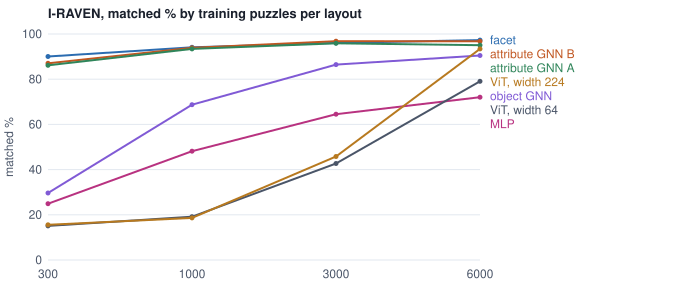

In [8]:
N = (300, 1000, 3000, 6000)
curves = {
    "facet": [facet(f"facet_cmp_n{n}") for n in N[:3]] + [facet("facet_all_w32-64-128_hidden")],
    "attribute GNN B": [torch_run(f"iraven_attr-rel_n{n}") for n in N[:3]] + [torch_run("iraven_attr-rel_reg_do0_wd0.5")],
    "attribute GNN A": [torch_run(f"iraven_attr-abs_n{n}") for n in N[:3]] + [torch_run("iraven_attr-abs_reg_do0_wd0.5")],
    "object GNN": [torch_run(f"iraven_gnn_n{n}") for n in N[:3]] + [torch_run("iraven_gnn_reg_do0_wd0.5", (0, 1))],
    "MLP": [torch_run(f"iraven_mlp_n{n}") for n in N[:3]] + [torch_run("iraven_mlp_reg_do0_wd0.5", (0, 1))],
    "ViT, width 64": [torch_run(f"iraven_vit_n{n}") for n in N[:3]] + [torch_run("iraven_vit_wd0.05_do0.1")],
    "ViT, width 224": [torch_run(f"iraven_vit_x16_n{n}") for n in N[:3]] + [torch_run("iraven_vit_x16_wd0.05_do0.1")],
}
table(["puzzles"] + list(curves), [[n] + [cell(curves[k][i]) for k in curves] for i, n in enumerate(N)])
display(chart([(k, [(i, v[0]) for i, v in enumerate(c)]) for k, c in curves.items()],
              "I-RAVEN, matched % by training puzzles per layout", list(enumerate(N)), 3))

## 3. How the models compare

The "strongest object-level" row is picked here as in the results file: among all MLP and object-GNN settings on a
dataset (1× to 64×, with and without regularization, seeds averaged), the one with the highest selection score.

In [9]:
def strongest(ds):
    groups = {}
    for d in glob.glob(f"{RUNS}/{ds}_mlp*") + glob.glob(f"{RUNS}/{ds}_gnn*"):
        name = re.sub(r"_s\d$", "", os.path.basename(d))
        if not re.search(r"_n\d+$|holdPS|noUD|_rows|_de0", name):
            groups.setdefault(name, []).append(json.load(open(f"{d}/best.json"))["best"])
    best = max(groups, key=lambda k: np.mean([b["sel"]["matched"] for b in groups[k]]))
    g = groups[best]
    return np.mean([100 * b["unseen"]["matched"] for b in g]), np.mean([100 * b["unseen"]["exact"] for b in g]), best

DS = ["iraven", "iravenx_n3_m10", "iravenx_n10_m50", "iravenx_n10_m100", "iravenx_n10_m1000"]
FX = ["all", "iravenx_n3_m10", "iravenx_n10_m50", "iravenx_n10_m100", "iravenx_n10_m1000"]
def frow(name, dirs):
    return [name] + [cell(facet(d)) if d else "–" for d in dirs]
reg = lambda ds: "do0_wd0.5" if ds == "iraven" else "do0.3_wd0.5"
rows = [frow("facet, named columns", ["facet_all_w32-64-128_hidden"] + [f"facet_{d}" for d in FX[1:]]),
        frow("+ copy links, per-panel gates *", ["facet_all_copy"] + [f"facet_{d}_copy" for d in FX[1:]]),
        frow("+ copy links, content gates", ["facet_all_copy_content", "facet_iravenx_n3_m10_copy_content",
                                             "facet_iravenx_n10_m50_copy_content", None, None]),
        frow("column roles + content gates", [None, None, "facet_iravenx_n10_m50_roles_content", None, None]),
        frow("row fold", ["facet_ep80_fold_all", "facet_iravenx_n3_m10_fold", "facet_iravenx_n10_m50_fold", None, None]),
        ["MLP, regularized (2 seeds)"] + [cell(torch_run(f"{ds}_mlp_reg_{reg(ds)}", (0, 1))) for ds in DS],
        ["object GNN, regularized (2 seeds)"] + [cell(torch_run(f"{ds}_gnn_reg_{reg(ds)}", (0, 1))) for ds in DS],
        ["strongest object-level, any size"] + [cell(strongest(ds)[:2]) for ds in DS],
        ["attribute GNN A", cell(torch_run("iraven_attr-abs_reg_do0_wd0.5")), "–",
         cell(torch_run("iravenx_n10_m50_attr-abs_reg_do0.3_wd0.5")) + " **", "–", "–"],
        ["attribute GNN B (symmetric)", cell(torch_run("iraven_attr-rel_reg_do0_wd0.5")), "–",
         cell(torch_run("iravenx_n10_m50_attr-rel_reg_do0.3_wd0.5")), "–", "–"],
        ["ViT, width 224, end to end", cell(torch_run("iraven_vit_x16_wd0.05_do0.1")),
         cell(torch_run("iravenx_n3_m10_vit_w224")), cell(torch_run("iravenx_n10_m50_vit_w224")), "–", "–"]]
va = lambda d: f"{100 * json.load(open(f'{E}/{d}/best.json'))['unseen']['matched']:.1f}"
symb = json.load(open(f"{E}/symb_e2e_rules_test.json"))["results"]["OVERALL"]
rows += [["value axis, building blocks given (matched)", va("valaxis_iraven"), va("valaxis_n3_m10_plus"),
          va("valaxis_n10_m50_plus"), "–", "–"],
         ["symbolic template, rules given", f"{symb['xml']:.2f} test; {symb['end2end']:.2f} end to end", "–", "–", "–", "–"],
         ["ARLC, learned (reported, other protocol)", "92.6", "98.4", "95.0", "95.0", "90.6"]]
table(["model", "I-RAVEN", "3×3, 0–10", "3×10, 0–50", "3×10, 0–100", "3×10, 0–1000"], rows)
print("strongest object-level setting per dataset:", {ds: strongest(ds)[2] for ds in DS})

| model | I-RAVEN | 3×3, 0–10 | 3×10, 0–50 | 3×10, 0–100 | 3×10, 0–1000 |
|---|---|---|---|---|---|
| facet, named columns | 97.3 (69.1) | 99.2 (92.7) | 85.4 (15.0) | 84.9 (6.4) | 81.2 (0.0) |
| + copy links, per-panel gates * | 98.2 (72.1) | 99.8 (95.0) | 97.8 (60.0) | 96.2 (30.8) | 94.3 (15.0) |
| + copy links, content gates | 97.4 (68.7) | 99.8 (94.2) | 94.9 (51.7) | – | – |
| column roles + content gates | – | – | 96.3 (43.3) | – | – |
| row fold | 95.8 (63.0) | 99.6 (94.5) | 92.2 (28.0) | – | – |
| MLP, regularized (2 seeds) | 72.0 (27.5) | 95.1 (74.3) | 84.5 (2.7) | 76.3 (0.1) | 73.8 (0.0) |
| object GNN, regularized (2 seeds) | 90.5 (55.1) | 93.9 (67.7) | 85.3 (4.2) | 76.8 (0.2) | 55.1 (0.0) |
| strongest object-level, any size | 93.8 (63.7) | 92.8 (64.8) | 86.4 (2.1) | 80.0 (0.5) | 74.3 (0.0) |
| attribute GNN A | 95.0 (62.5) | – | 95.0 (27.7) ** | – | – |
| attribute GNN B (symmetric) | 96.8 (67.9) | – | 85.8 (3.5) | – | – |
| ViT, width 224, end to end | 93.4 (64.4) | 47.5 (5.6) | 43.1 (0.4) | – | – |
| value axis, building blocks given (matched) | 99.3 | 99.8 | 100.0 | – | – |
| symbolic template, rules given | 98.33 test; 96.31 end to end | – | – | – | – |
| ARLC, learned (reported, other protocol) | 92.6 | 98.4 | 95.0 | 95.0 | 90.6 |

strongest object-level setting per dataset: {'iraven': 'iraven_gnn_x16_reg_do0_wd0.5', 'iravenx_n3_m10': 'iravenx_n3_m10_mlp', 'iravenx_n10_m50': 'iravenx_n10_m50_mlp_x16', 'iravenx_n10_m100': 'iravenx_n10_m100_mlp', 'iravenx_n10_m1000': 'iravenx_n10_m1000_mlp'}


\* Per-panel gates learned Distribute by address on 3×10 (section 4). \*\* GNN A's 3×10 lead is the same shortcut. The
value axis is given `plus`, value counts and offsets, so it is not ranked with the learned models; its exact is read in
section 7.

**Exact value per rule on 3×10, values 0–50**, for the runs that store it (the facet runs' per-rule scores come from
`core/pynl/facet_rule_eval.py`, about ten minutes per checkpoint, and are in `docs/RESULTS.md` §5).

In [10]:
RULES = ("Constant", "Progression", "Distribute_Three", "Arithmetic")
def per_rule(d, seeds=(0,)):
    rs = [json.load(open(f"{RUNS}/{d}_s{s}/best.json"))["best"]["unseen"] for s in seeds]
    return [f"{np.mean([rule_exact(r, k) for r in rs]):.1f}" for k in RULES]
vnp = json.load(open(f"{E}/valaxis_n10_m50_noplus/best.json"))["unseen"]["per_rule"]
table(["model"] + list(RULES),
      [["attribute GNN A"] + per_rule("iravenx_n10_m50_attr-abs_reg_do0.3_wd0.5"),
       ["attribute GNN B"] + per_rule("iravenx_n10_m50_attr-rel_reg_do0.3_wd0.5"),
       ["object GNN, regularized (2 seeds)"] + per_rule("iravenx_n10_m50_gnn_reg_do0.3_wd0.5", (0, 1)),
       ["MLP, regularized (2 seeds)"] + per_rule("iravenx_n10_m50_mlp_reg_do0.3_wd0.5", (0, 1)),
       ["value axis without plus"] + [f"{100 * vnp[k]:.1f}" for k in RULES]])

| model | Constant | Progression | Distribute_Three | Arithmetic |
|---|---|---|---|---|
| attribute GNN A | 95.2 | 73.9 | 59.9 | 18.0 |
| attribute GNN B | 54.7 | 39.4 | 12.3 | 22.7 |
| object GNN, regularized (2 seeds) | 58.4 | 43.2 | 24.9 | 10.7 |
| MLP, regularized (2 seeds) | 50.3 | 34.2 | 19.8 | 10.5 |
| value axis without plus | 100.0 | 100.0 | 100.0 | 11.1 |

## 4. Symmetries of the datasets

**Which rule instances survive a transformation**, counted on the first 1000 puzzles of each I-RAVEN-X file
(`analysis/dataset_symmetry_check.py`). A transformation that keeps 100% of a rule is a task symmetry for it; whether it is also
a data symmetry depends on the generator's statistics. On 3×10, rows 1 ↔ 2 breaks Distribute as generated: its rows are
row 1 shifted by a constant step, and after the swap no step fits ("any step" allows a different one), so the generator
never produces the swapped puzzle. The answer, the one value row 3 lacks, stays right, so the swap is still a task
symmetry.

In [11]:
import dataset_symmetry_check as DSC
for path in ["data/iravenx/center_single_shuffle_n_3_maxval_10.json", "data/iravenx/center_single_shuffle_n_10_maxval_50.json"]:
    m, k, surv, *_ = DSC.iravenx(path, 1000)
    names = ["rows 1<>2", "cols 1<>2", "reflect values"] + (["cols 2<>3"] if k > 3 else [])
    fams = sorted({f for _, f, _ in surv})
    display(Markdown(f"**I-RAVEN-X {k}×{k}, values 0–{m}**"))
    table(["rule"] + names, [[f] + [f"{100 * surv[(t, f, 'value')]['ok'] / surv[(t, f, 'value')]['n']:.0f}"
                                    if surv.get((t, f, "value")) else "" for t in names] for f in fams])

**I-RAVEN-X 3×3, values 0–10**

| rule | rows 1<>2 | cols 1<>2 | reflect values |
|---|---|---|---|
| Arithmetic | 100 | 57 | 0 |
| Constant | 100 | 100 | 100 |
| Distribute_Three | 100 | 100 | 100 |
| Distribute_Three (any step) | 100 | 100 | 100 |
| Progression | 100 | 0 | 100 |

**I-RAVEN-X 10×10, values 0–50**

| rule | rows 1<>2 | cols 1<>2 | reflect values | cols 2<>3 |
|---|---|---|---|---|
| Arithmetic | 100 | 52 | 0 | 100 |
| Constant | 100 | 100 | 100 | 100 |
| Distribute_Three | 0 | 0 | 100 | 0 |
| Distribute_Three (any step) | 0 | 0 | 100 | 0 |
| Progression | 100 | 0 | 100 | 0 |

**One symmetry removed at a time** (the facet model): shared and exact; the symmetry broken by labels while every weight
stays shared; separate weights at the same widths; separate weights at the same weight count.

In [12]:
def abl(prefix, n, base=None):
    return [cell(facet(base or f"facet_symabl_{prefix}_base_{n}"))] + [cell(facet(f"facet_symabl_{prefix}_{v}_{n}"))
                                                                      for v in ("lab", "sep", "sepm")]
table(["symmetry, puzzles", "shared", "labels", "separate, same widths", "separate, same weights"],
      [[f"components (I-RAVEN left-right + up-down), {n} per layout"] + abl("lrud", n) for n in (100, 1000, 6000)]
      + [["attributes (3×10, column roles), 600"] + abl("irx", 600),
         ["attributes (3×10, column roles), 6000"] + abl("irx", 6000, "facet_iravenx_n10_m50_roles")])

| symmetry, puzzles | shared | labels | separate, same widths | separate, same weights |
|---|---|---|---|---|
| components (I-RAVEN left-right + up-down), 100 per layout | 86.6 (40.4) | 87.3 (41.3) | 75.6 (22.2) | 74.6 (19.6) |
| components (I-RAVEN left-right + up-down), 1000 per layout | 99.3 (95.6) | 99.6 (95.7) | 97.9 (84.5) | 98.5 (84.5) |
| components (I-RAVEN left-right + up-down), 6000 per layout | 99.9 (97.7) | 99.8 (98.7) | 100.0 (97.8) | 100.0 (98.8) |
| attributes (3×10, column roles), 600 | 66.3 (16.4) | 64.6 (14.1) | 52.5 (4.1) | 53.0 (3.6) |
| attributes (3×10, column roles), 6000 | 94.1 (29.0) | 93.9 (28.5) | 90.5 (17.8) | 88.1 (17.6) |

**The same puzzles transformed** (I-RAVEN-X 3×10, matched %). Rows 1 ↔ 2 is only a task symmetry there, so every model
that does not have it built in can use an address shortcut, and falls when the rows are swapped. The facet variants with
the symmetry give identical answers (section 1).

In [13]:
tr = [("attribute GNN B (symmetric)", "iravenx_n10_m50_attr-rel_reg_do0.3_wd0.5"),
      ("attribute GNN A", "iravenx_n10_m50_attr-abs_reg_do0.3_wd0.5"),
      ("object GNN, regularized", "iravenx_n10_m50_gnn_reg_do0.3_wd0.5"),
      ("MLP, regularized", "iravenx_n10_m50_mlp_reg_do0.3_wd0.5"),
      ("ViT, width 224", "iravenx_n10_m50_vit_w224"), ("ViT, width 224, rows built in", "iravenx_n10_m50_vit-sym_w224"),
      ("ViT, width 64", "iravenx_n10_m50_vit_w64")]
table(["model", "as is", "rows 1 ↔ 2", "middle columns 2 ↔ 3"],
      [[n, f"{torch_run(d)[0]:.1f}", f"{torch_run(d, key='rows12')[0]:.1f}", f"{torch_run(d, key='cols23')[0]:.1f}"] for n, d in tr])

| model | as is | rows 1 ↔ 2 | middle columns 2 ↔ 3 |
|---|---|---|---|
| attribute GNN B (symmetric) | 85.8 | 85.8 | 85.8 |
| attribute GNN A | 95.0 | 55.5 | 82.0 |
| object GNN, regularized | 84.0 | 52.7 | 71.6 |
| MLP, regularized | 84.4 | 47.7 | 63.9 |
| ViT, width 224 | 43.1 | 37.9 | 44.4 |
| ViT, width 224, rows built in | 40.1 | 40.1 | 39.9 |
| ViT, width 64 | 52.9 | 38.5 | 47.3 |

**A layout never seen.** Trained without up-down and scored on it (I-RAVEN). The models that share weights across
components solve it; the others are near chance (12.5). The facet model's 99.1 comes from its own evaluation log.

In [14]:
UD = "up_center_single_down_center_single"
ud = lambda d: (lambda h, t: 100 * h / t)(*json.load(open(f"{RUNS}/{d}_s0/best.json"))["best"]["unseen"]["per_constellation"][UD])
table(["model trained without up-down"] + ["matched on up-down"],
      [[n, f"{ud(d):.1f}"] for n, d in [("attribute GNN B", "iraven_attr-rel_noUD"), ("attribute GNN A", "iraven_attr-abs_noUD"),
                                        ("object GNN", "iraven_gnn_noUD"), ("MLP", "iraven_mlp_noUD"),
                                        ("ViT, width 224", "iraven_vit_x16_noUD"), ("ViT, width 224, rows built in", "iraven_vit-sym_x16_noUD")]])

| model trained without up-down | matched on up-down |
|---|---|
| attribute GNN B | 99.5 |
| attribute GNN A | 99.9 |
| object GNN | 23.6 |
| MLP | 13.3 |
| ViT, width 224 | 14.0 |
| ViT, width 224, rows built in | 13.7 |

## 5. Symmetries of the rules

**Which rows of a rule survive a change of the values**, applied alike to every panel (rows of 3, values 0–50;
`data_prep/rule_twins.py`). Midpoint is sum's twin: as many rows, and it keeps the shift. Lookup is a table with no symmetry.

In [15]:
import random
import rule_twins as RT
M = 50
g = RT.lookup_table(M)
rows4 = {r: RT.table(r, M, g) for r in RT.TWINS}
rand = list(range(M + 1)); random.Random(1).shuffle(rand)
changes = {"shift +1": lambda t: [v + 1 for v in t], "shift +7": lambda t: [v + 7 for v in t],
           "reflect": lambda t: [M - v for v in t], "relabel": lambda t: [rand[v] for v in t],
           "swap a, b": lambda t: [t[1], t[0], t[2]]}
table(["rule", "rows"] + list(changes),
      [[r, len(rows4[r])] + [f"{100 * h / max(n, 1):.0f}" for h, n in (RT.keeps(rows4[r], fn, M) for fn in changes.values())]
       for r in RT.TWINS])

| rule | rows | shift +1 | shift +7 | reflect | relabel | swap a, b |
|---|---|---|---|---|---|---|
| sum | 1225 | 0 | 0 | 0 | 1 | 100 |
| midpoint | 1250 | 100 | 100 | 100 | 1 | 100 |
| mirror | 1250 | 100 | 100 | 100 | 1 | 0 |
| lookup | 51 | 0 | 0 | 0 | 0 | 0 |

**The rule-twin test.** I-RAVEN-X with Arithmetic replaced by the test rule; no model is given `plus`. Exact % on the test
rule, epoch picked by exact on the selection puzzles (read from `history.json`). "Memorising" is computed here, with
nothing trained: an unseen question row counts as solved only if the same operands were the question row of a training
puzzle, since only the answer panel has a loss.

| model, at 100 / 600 / 6000 puzzles | sum | midpoint | mirror | lookup |
|---|---|---|---|---|
| shared, shift-equivariant (14.8k weights) | 4.7 / 6.9 / 7.1 | 57.4 / 89.3 / 92.7 | 45.3 / 78.3 / 88.1 | 35.9 / 74.3 / 77.7 |
| weights per value (460k) | 4.9 / 19.3 / 69.8 | 5.7 / 17.8 / 75.2 | 4.6 / 15.7 / 63.2 | 53.0 / 97.5 / 97.5 |
| memorising answered rows, untrained | 4.7 / 24.1 / 90.7 | 5.0 / 21.6 / 90.5 | 4.0 / 19.7 / 91.7 | 65.3 / 100.0 / 100.0 |

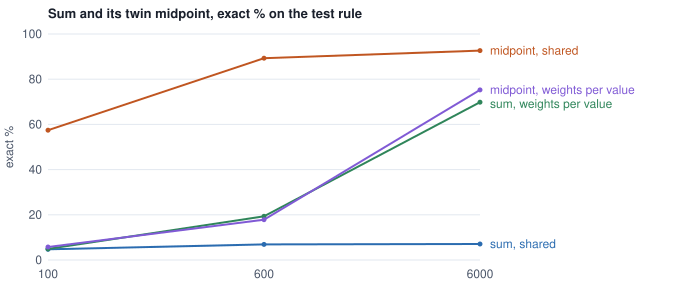

In [16]:
def twin(model, rule, n):
    h = json.load(open(f"{E}/twins/{model}_{rule}_n{n}/history.json"))
    return 100 * max(h, key=lambda r: r["sel"]["exact"])["unseen"]["per_rule"]["Arithmetic"]
NT = (100, 600, 6000)
def memorise(rule):
    d = json.load(open(RT.path_of(rule, M)))
    unseen = [rows[2] for rows in RT.question_rows(d, 6300, 7300)]
    key = (lambda q: q[1]) if rule == "lookup" else (lambda q: (q[0], q[1]))
    out = {}
    for n in NT:
        seen = {key(rows[2]): rows[2][2] for rows in RT.question_rows(d, 0, n)}
        out[n] = 100 * sum(seen.get(key(q)) == q[2] for q in unseen) / len(unseen)
    return out
memo = {r: memorise(r) for r in RT.TWINS}
res = {"shared, shift-equivariant (14.8k weights)": {r: [twin("shared", r, n) for n in NT] for r in RT.TWINS},
       "weights per value (460k)": {r: [twin("pervalue", r, n) for n in NT] for r in RT.TWINS},
       "memorising answered rows, untrained": {r: [memo[r][n] for n in NT] for r in RT.TWINS}}
table(["model, at 100 / 600 / 6000 puzzles"] + list(RT.TWINS),
      [[k] + [" / ".join(f"{v:.1f}" for v in res[k][r]) for r in RT.TWINS] for k in res])
display(chart([(f"{r}, {k.split(',')[0].split(' (')[0]}", [(i, v) for i, v in enumerate(res[k][r])])
               for k in list(res)[:2] for r in ("sum", "midpoint")],
              "Sum and its twin midpoint, exact % on the test rule", list(enumerate(NT)), 2, ylabel="exact %"))

## 6. Why Arithmetic is hard

**A shift breaks a sum.** A rule c = p·a + q·b survives "every panel + s" exactly when p + q = 1: the shifted answer is
c + (p + q)s, and it should be c + s.

In [17]:
for name, p, q in [("plus, c = a + b", 1, 1), ("minus, c = a − b", 1, -1), ("midpoint, c = (a + b)/2", .5, .5),
                   ("Progression, c = 2b − a", -1, 2)]:
    a, b, s = 10, 20, 5
    c, c2 = p * a + q * b, p * (a + s) + q * (b + s)
    print(f"{name:26s} p + q = {p + q:4}:  {a}, {b} -> {c:g};  shifted by {s}: {a + s}, {b + s} -> {c2:g}, "
          f"{'holds' if c2 == c + s else 'breaks'}")

plus, c = a + b            p + q =    2:  10, 20 -> 30;  shifted by 5: 15, 25 -> 40, breaks
minus, c = a − b           p + q =    0:  10, 20 -> -10;  shifted by 5: 15, 25 -> -10, breaks
midpoint, c = (a + b)/2    p + q =  1.0:  10, 20 -> 15;  shifted by 5: 15, 25 -> 20, holds
Progression, c = 2b − a    p + q =    1:  10, 20 -> 30;  shifted by 5: 15, 25 -> 35, holds


**What a shift-equivariant model can do.** If f(a + s, b + s) = f(a, b) + s, then f(a, b) = b + h(b − a): the model can
only take a step from b, chosen from the first step b − a. Count the rows on values 0–50 (a, b ≥ 1): how many first steps
there are, and how many rows such a model can get right at best. For midpoint the needed step is fixed by the first step,
so the table collapses.

In [18]:
for rule in ("sum", "midpoint"):
    by_step = {}
    for a, b, c in rows4[rule]:
        by_step.setdefault(b - a, Counter())[c - b] += 1
    best = sum(cnt.most_common(1)[0][1] for cnt in by_step.values())
    print(f"{rule:9s}: {len(rows4[rule]):5d} rows on {len(by_step)} first steps; a step chosen from the first step alone "
          f"gets {best} rows right = {100 * best / len(rows4[rule]):.1f}%")

sum      :  1225 rows on 97 first steps; a step chosen from the first step alone gets 97 rows right = 7.9%
midpoint :  1250 rows on 50 first steps; a step chosen from the first step alone gets 1250 rows right = 100.0%


**Addition's own symmetries.** A row stays valid when a, b and c move by s, t and s + t. Starting from 0 + 0 = 0, these
moves reach every fact of the table on 0–50, while moving every panel alike keeps none of them.

In [19]:
plus = {(a, b, a + b) for a in range(51) for b in range(51) if a + b <= 50}
reached = {(s, t, s + t) for s in range(51) for t in range(51) if s + t <= 50}        # (0, 0, 0) moved by (s, t, s + t)
uniform = [(a + 1, b + 1, c + 1) for a, b, c in plus if c + 1 <= 50]
print(f"plus facts on 0-50: {len(plus)}; reached from 0 + 0 = 0 by the moves (s, t, s + t): {len(reached & plus)}")
print(f"every panel + 1: {sum(t in plus for t in uniform)} of {len(uniform)} facts still hold")

plus facts on 0-50: 1326; reached from 0 + 0 = 0 by the moves (s, t, s + t): 1326
every panel + 1: 0 of 1275 facts still hold


**Why a GNN can still learn a sum.** In thermometer codes (value v = the first v bits on) unit i of the answer is on
exactly when a + b > i, and a + b is the number of ones in the two codes together. So one linear layer with every weight 1
and a threshold per unit computes the sum. The same holds for plus and minus over nine operands, with weights +1 and −1.

In [20]:
T = 51
therm = lambda v: (np.arange(T) < v).astype(float)
pairs = [(a, b) for a in range(51) for b in range(51) if a + b <= 50]
layer = lambda x: (x.sum() - np.arange(T) - 0.5 > 0).astype(float)                     # weights 1, bias -i - 0.5
print("a + b, all", len(pairs), "pairs:", all((layer(np.concatenate([therm(a), therm(b)])) == therm(a + b)).all() for a, b in pairs))
rng = np.random.default_rng(0)
ok = 0
for _ in range(2000):                                                                  # I-RAVEN-X minus: c10 = c1 - (c2 + ... + c9)
    mid = rng.integers(0, 6, 8); first = mid.sum() + rng.integers(0, 51 - mid.sum())
    x = therm(first).sum() - sum(therm(v).sum() for v in mid)
    ok += ((x - np.arange(T) - 0.5 > 0).astype(float) == therm(first - mid.sum())).all()
print("first - eight others, 2000 random rows:", ok == 2000)

a + b, all 1326 pairs: True
first - eight others, 2000 random rows: True


**Plus and minus apart** (column roles; the two-operator checkpoint scored on the same unseen puzzles). Read from the job
logs of `jobs/pynl/submit_arith_op.sh`.

In [21]:
pm = []
for op in ("plus", "minus"):
    run = None
    for line in open(sorted(glob.glob(f"log/arith_op_arith_{op}_*.out"))[-1]):
        if line.startswith("experiments/") and " weights, " in line:
            run = line.split(":")[0]
        elif "exact value:" in line and run:
            ar, n = re.search(r"Arithmetic ([\d.]+) \(of (\d+)\)", line).groups()
            pm.append([op, "both operators" if run.endswith("_roles") else f"{op} only", ar, n])
table(["unseen puzzles with", "trained on", "Arithmetic exact", "attributes"], pm)

| unseen puzzles with | trained on | Arithmetic exact | attributes |
|---|---|---|---|
| plus | plus only | 35.0 | 206 |
| plus | both operators | 49.5 | 206 |
| minus | minus only | 34.2 | 228 |
| minus | both operators | 29.8 | 228 |

**Does Arithmetic fall to more data and weight decay (grokking)?** Attribute GNN B at 16× (25.6M weights) on 3×10
puzzles where every attribute follows Arithmetic. Grokking would be train at 100 long before unseen rises.

| training puzzles | steps run | best: train / unseen | last: train / unseen |
|---|---|---|---|
| 100 puzzles, no decay | 300k | 100.0 / 6.4 | 100.0 / 6.4 |
| 100 puzzles, decay 0.1 | 300k | 100.0 / 10.4 | 94.3 / 10.0 |
| 300 puzzles, decay 0.1 | 300k | 100.0 / 61.7 | 86.6 / 28.6 |
| 1000 puzzles, no decay | 18k | 99.8 / 98.3 | 99.3 / 98.1 |
| 1000 puzzles, decay 0.1 | 18k | 99.7 / 97.0 | 99.9 / 96.3 |
| 3000 puzzles, decay 0.1 | 12k | 99.1 / 99.0 | 99.1 / 99.0 |
| 100,000 puzzles, decay 0.1 | 180k | 99.2 / 99.3 | 43.2 / 43.8 |

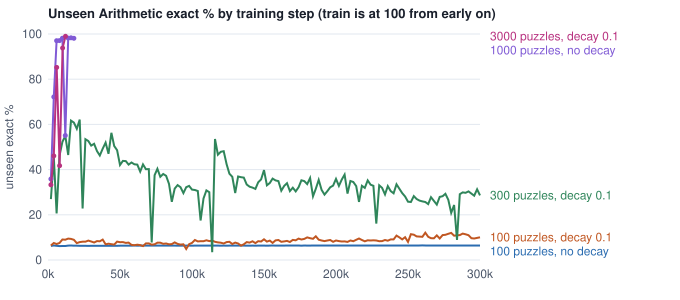

In [22]:
def grok(tag):
    d = f"{RUNS}/iravenx_arith_attr-rel_x16_{tag}_s0"
    info = json.load(open(f"{d}/best.json")); per = -(-info["samples"]["train"] // 64)
    return [(r["epoch"] * per / 1000, rule_exact(r["train"], "Arithmetic"), rule_exact(r["unseen"], "Arithmetic"))
            for r in json.load(open(f"{d}/history.json"))], info
runs = [("100 puzzles, no decay", "grok_n100_wd0"), ("100 puzzles, decay 0.1", "grok_n100_wd0.1"),
        ("300 puzzles, decay 0.1", "grok_n300_wd0.1"), ("1000 puzzles, no decay", "grok_n1000_wd0"),
        ("1000 puzzles, decay 0.1", "grok_n1000_wd0.1"), ("3000 puzzles, decay 0.1", "grok_n3000_wd0.1"),
        ("100,000 puzzles, decay 0.1", "grok_do0_wd0.1")]
rows, series = [], []
for name, tag in runs:
    h, info = grok(tag)
    b = info["best"]
    rows.append([name, f"{h[-1][0]:.0f}k", f"{rule_exact(b['train'], 'Arithmetic'):.1f} / {rule_exact(b['unseen'], 'Arithmetic'):.1f}",
                 f"{h[-1][1]:.1f} / {h[-1][2]:.1f}"])
    if "1000 puzzles, decay" not in name and "100,000" not in name:
        series.append((name, [(s, u) for s, _, u in h if s <= 300]))
table(["training puzzles", "steps run", "best: train / unseen", "last: train / unseen"], rows)
display(chart(series, "Unseen Arithmetic exact % by training step (train is at 100 from early on)",
              [(x, f"{x}k") for x in (0, 50, 100, 150, 200, 250, 300)], 300, ylabel="unseen exact %"))

## 7. The value-axis model

Values are constants on an axis, and a convolution runs along it: one learned code per offset −2 … +2, and scoring layers
with the same weights at every value. It is given `plus`, value counts per row and the offsets, and learns which rule holds.
Exact per rule is the argmax of its value distribution (`best.json` `per_rule`). The model in detail:
`notebooks/value_axis.ipynb`.

| 3×10, values 0–50 | weights | matched | Constant | Progression | Distribute_Three | Arithmetic |
|---|---|---|---|---|---|---|
| shared, 100 puzzles | 10.8k | 99.0 | 99.9 | 98.5 | 100.0 | 97.2 |
| shared, 600 puzzles | 10.8k | 99.9 | 100.0 | 100.0 | 100.0 | 99.8 |
| shared, 6000 puzzles | 10.8k | 100.0 | 100.0 | 100.0 | 100.0 | 100.0 |
| shared, 6000, without plus | 10.7k | 84.0 | 100.0 | 100.0 | 100.0 | 11.1 |
| weights per value, 100 | 335.5k | 38.3 | 60.5 | 30.8 | 21.4 | 22.3 |
| weights per value, 600 | 335.5k | 92.7 | 98.0 | 87.8 | 97.7 | 86.8 |
| weights per value, 6000 | 335.5k | 98.4 | 100.0 | 100.0 | 100.0 | 94.9 |
| 3×3, values 0–10, 6000 | 10.8k | 99.8 | 100.0 | 100.0 | 100.0 | 99.4 |

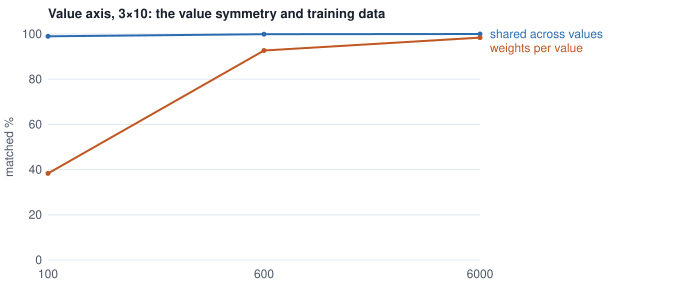

In [23]:
def va_row(name, d):
    b = json.load(open(f"{E}/{d}/best.json"))
    u = b["unseen"]
    return [name, f"{b['weights'] / 1000:.1f}k", f"{100 * u['matched']:.1f}"] + [f"{100 * u['per_rule'][k]:.1f}" for k in RULES]
table(["3×10, values 0–50", "weights", "matched"] + list(RULES),
      [va_row("shared, 100 puzzles", "valaxis_n10_m50_plus100"), va_row("shared, 600 puzzles", "valaxis_n10_m50_plus600"),
       va_row("shared, 6000 puzzles", "valaxis_n10_m50_plus"), va_row("shared, 6000, without plus", "valaxis_n10_m50_noplus"),
       va_row("weights per value, 100", "valaxis_n10_m50_pervalue100"), va_row("weights per value, 600", "valaxis_n10_m50_pervalue600"),
       va_row("weights per value, 6000", "valaxis_n10_m50_pervalue"), va_row("3×3, values 0–10, 6000", "valaxis_n3_m10_plus")])
m = lambda d: 100 * json.load(open(f"{E}/{d}/best.json"))["unseen"]["matched"]
display(chart([("shared across values", [(i, m(d)) for i, d in enumerate(["valaxis_n10_m50_plus100", "valaxis_n10_m50_plus600", "valaxis_n10_m50_plus"])]),
               ("weights per value", [(i, m(d)) for i, d in enumerate(["valaxis_n10_m50_pervalue100", "valaxis_n10_m50_pervalue600", "valaxis_n10_m50_pervalue"])])],
              "Value axis, 3×10: the value symmetry and training data", list(enumerate(NT)), 2))

## 8. Perception and the symbolic level

The symbolic template with RAVEN's rules given (41 weights), on the I-RAVEN test split, from the XML labels and end to end
through the ResNet-18 frontend; `all 16 perceived` is the share of puzzles whose 16 panels the frontend reads exactly.

In [24]:
res = json.load(open(f"{E}/symb_e2e_rules_test.json"))["results"]
table(["layout", "all 16 perceived", "XML labels", "end to end"],
      [[k, f"{v['all16_perceived']:.1f}", f"{v['xml']:.2f}", f"{v['end2end']:.2f}"] for k, v in res.items()])

| layout | all 16 perceived | XML labels | end to end |
|---|---|---|---|
| center_single | 100.0 | 99.90 | 99.90 |
| distribute_four | 99.9 | 95.98 | 95.94 |
| distribute_nine | 76.5 | 95.46 | 85.44 |
| left_center_single_right_center_single | 100.0 | 99.95 | 99.95 |
| up_center_single_down_center_single | 100.0 | 99.95 | 99.95 |
| in_center_single_out_center_single | 100.0 | 99.85 | 99.85 |
| in_distribute_four_out_center_single | 71.5 | 97.26 | 93.16 |
| OVERALL | 92.6 | 98.33 | 96.31 |